<center><h1>Keehan_Alyssa_HW7</h1></center>

Name: Alyssa Keehan
<br>
Github Username: akeehan56
<br>
GitHub Links: [Class Repo](https://github.com/akeehan56/DSCI552) | [HW7](https://github.com/akeehan56/DSCI552/tree/main/HW7)
<br>
Email: akeehan@usc.edu
<br>
USC ID: 3429542433

## 1. Multi-class and Multi-Label Classification Using Support Vector Machines

Import packages

In [2]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC, LinearSVC
from sklearn.multiclass import OneVsRestClassifier
from sklearn.metrics import (
    accuracy_score,
    hamming_loss,
    confusion_matrix,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, calinski_harabasz_score

from sklearn.multioutput import ClassifierChain
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline

### (a) Download the Anuran Calls (MFCCs) Data Set

In [3]:
df = pd.read_csv(Path("../data/Anuran Calls (MFCCs)", "Frogs_MFCCs.csv"))
df.head(10)

,MFCCs_ 1,MFCCs_ 2,MFCCs_ 3,MFCCs_ 4,MFCCs_ 5,MFCCs_ 6,MFCCs_ 7,MFCCs_ 8,MFCCs_ 9,MFCCs_10,...,MFCCs_17,MFCCs_18,MFCCs_19,MFCCs_20,MFCCs_21,MFCCs_22,Family,Genus,Species,RecordID
0,1.0,0.152936,-0.105586,0.200722,0.317201,0.260764,0.100945,-0.150063,-0.171128,0.124676,...,-0.108351,-0.077623,-0.009568,0.057684,0.118680,0.014038,Leptodactylidae,Adenomera,AdenomeraAndre,1
1,1.0,0.171534,-0.098975,0.268425,0.338672,0.268353,0.060835,-0.222475,-0.207693,0.170883,...,-0.090974,-0.056510,-0.035303,0.020140,0.082263,0.029056,Leptodactylidae,Adenomera,AdenomeraAndre,1
2,1.0,0.152317,-0.082973,0.287128,0.276014,0.189867,0.008714,-0.242234,-0.219153,0.232538,...,-0.050691,-0.023590,-0.066722,-0.025083,0.099108,0.077162,Leptodactylidae,Adenomera,AdenomeraAndre,1
3,1.0,0.224392,0.118985,0.329432,0.372088,0.361005,0.015501,-0.194347,-0.098181,0.270375,...,-0.136009,-0.177037,-0.130498,-0.054766,-0.018691,0.023954,Leptodactylidae,Adenomera,AdenomeraAndre,1
4,1.0,0.087817,-0.068345,0.306967,0.330923,0.249144,0.006884,-0.265423,-0.172700,0.266434,...,-0.048885,-0.053074,-0.088550,-0.031346,0.108610,0.079244,Leptodactylidae,Adenomera,AdenomeraAndre,1
5,1.0,0.099704,-0.033408,0.349895,0.344535,0.247569,0.022407,-0.213767,-0.127916,0.277353,...,-0.080487,-0.130089,-0.171478,-0.071569,0.077643,0.064903,Leptodactylidae,Adenomera,AdenomeraAndre,1
6,1.0,0.021676,-0.062075,0.318229,0.380439,0.179043,-0.041667,-0.252300,-0.167117,0.220027,...,-0.046620,-0.055146,-0.085972,-0.009127,0.065630,0.044040,Leptodactylidae,Adenomera,AdenomeraAndre,1
7,1.0,0.145130,-0.033660,0.284166,0.279537,0.175211,0.005791,-0.183329,-0.158483,0.192567,...,-0.055978,-0.048219,-0.056637,-0.022419,0.070085,0.021419,Leptodactylidae,Adenomera,AdenomeraAndre,1
8,1.0,0.271326,0.027777,0.375738,0.385432,0.272457,0.098192,-0.173730,-0.157857,0.207181,...,-0.120723,-0.112607,-0.156933,-0.118527,-0.002471,0.002304,Leptodactylidae,Adenomera,AdenomeraAndre,1
9,1.0,0.120565,-0.107235,0.316555,0.364437,0.307757,0.025992,-0.294179,-0.223236,0.268435,...,-0.051073,-0.052568,-0.111338,-0.040014,0.090204,0.088025,Leptodactylidae,Adenomera,AdenomeraAndre,1


In [4]:
df.columns = df.columns.str.strip()

target_cols = ["Family", "Genus", "Species"]

record_id_cols = [
    col for col in df.columns
    if col.lower().replace("_", "").replace(" ", "") == "recordid"
]

X = df.drop(columns=target_cols + record_id_cols)
y = df[target_cols]

# split the data: 70% training, 30% test

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    train_size=0.70,
    random_state=17
)

print("Training set:", X_train.shape, y_train.shape)
print("Test set:", X_test.shape, y_test.shape)

Training set: (5036, 22) (5036, 3)
Test set: (2159, 22) (2159, 3)


### (b) Train a classifier for each label

#### (i) Research

**Answer:**

- Exact Match counts an observation as correct only when all the labels for multi-class/label classification. This measure ignores partially correct labels which could be considered harsh.
- Hamming Loss is the fraction of the labels predicted incorectly, averaged over observations. The smaller the hamming loss, the better the performance as it takes into account both the prediction and missing error. 
- Hamming Score is the reciprocal of hamming loss, the proportion of predicted correct labels to the total number of labels for that instance. It is commonly known as accuracy.

Source: [Metrics for Multilable Classification](https://mmuratarat.github.io/2020-01-25/multilabel_classification_metrics)

#### (ii) Train a SVM for each of the labels

In [6]:
# Small search grid to reduce run time
C_values = [0.1, 10]
sigma_values = [0.5, 1.0]
gamma_values = [1 / (2 * sigma**2) for sigma in sigma_values]

rbf_models = {}
rbf_pred = pd.DataFrame(index=y_test.index)

for target in target_cols:
    pipe = ImbPipeline([
        ("model", OneVsRestClassifier(SVC(kernel="rbf")))
    ])

    search = GridSearchCV(
        pipe,
        param_grid={
            "model__estimator__C": C_values,
            "model__estimator__gamma": gamma_values
        },
        scoring="accuracy",
        cv=10,
        n_jobs=1
    )

    search.fit(X_train, y_train[target])

    rbf_models[target] = search.best_estimator_
    rbf_pred[target] = search.predict(X_test)

    print(
        target,
        "best parameters:", search.best_params_,
        "best CV accuracy:", search.best_score_
    )

Family best parameters: {'model__estimator__C': 10, 'model__estimator__gamma': 2.0} best CV accuracy: 0.9932496292088737
Genus best parameters: {'model__estimator__C': 10, 'model__estimator__gamma': 2.0} best CV accuracy: 0.9922555934235856
Species best parameters: {'model__estimator__C': 10, 'model__estimator__gamma': 2.0} best CV accuracy: 0.9916599608697025


#### (iii) Repeat 1(b)ii with L1-penalized SVMs

In [7]:
l1_models = {}
l1_pred = pd.DataFrame(index=y_test.index)

for target in target_cols:
    pipe = ImbPipeline([
        ("scaler", StandardScaler()),
        ("model", OneVsRestClassifier(
            LinearSVC(
                penalty="l1",
                loss="squared_hinge",
                dual=False,
                max_iter=20000,
                random_state=42
            )
        ))
    ])

    search = GridSearchCV(
        pipe,
        param_grid={"model__estimator__C": C_values},
        scoring="accuracy",
        cv=10,
        n_jobs=1
    )

    search.fit(X_train, y_train[target])

    l1_models[target] = search.best_estimator_
    l1_pred[target] = search.predict(X_test)

    print(
        target,
        "best parameters:", search.best_params_,
        "best CV accuracy:", search.best_score_
    )

Family best parameters: {'model__estimator__C': 10} best CV accuracy: 0.9320927608949479
Genus best parameters: {'model__estimator__C': 10} best CV accuracy: 0.9521462494872038
Species best parameters: {'model__estimator__C': 10} best CV accuracy: 0.9563164662816751


#### (iv) Repeat 1(b)iii by using SMOTE or any other method for imbalance

In [9]:
smote_models = {}
smote_pred = pd.DataFrame(index=y_test.index)

for target in target_cols:
    pipe = ImbPipeline([
        ("scaler", StandardScaler()),
        ("smote", SMOTE(random_state=42, k_neighbors=1)),
        ("model", OneVsRestClassifier(
            LinearSVC(
                penalty="l1",
                loss="squared_hinge",
                dual=False,
                max_iter=20000,
                random_state=42
            )
        ))
    ])

    search = GridSearchCV(
        pipe,
        param_grid={"model__estimator__C": C_values},
        scoring="accuracy",
        cv=10,
        n_jobs=1
    )

    search.fit(X_train, y_train[target])

    smote_models[target] = search.best_estimator_
    smote_pred[target] = search.predict(X_test)

    print(
        target,
        "best parameters:", search.best_params_,
        "best CV accuracy:", search.best_score_
    )

Family best parameters: {'model__estimator__C': 10} best CV accuracy: 0.9166035532834738
Genus best parameters: {'model__estimator__C': 10} best CV accuracy: 0.915809508031178


/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/sklearn/svm/_base.py:1295: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/sklearn/svm/_base.py:1295: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(


Species best parameters: {'model__estimator__C': 0.1} best CV accuracy: 0.9549256050995615


In [10]:
predictions_by_model = {
    "Gaussian SVM": rbf_pred,
    "L1 SVM": l1_pred,
    "L1 SVM with SMOTE": smote_pred
}

results = []

for model_name, predictions in predictions_by_model.items():
    true_joint = y_test[target_cols].astype(str).agg("|".join, axis=1)
    pred_joint = predictions[target_cols].astype(str).agg("|".join, axis=1)

    exact_match = accuracy_score(true_joint, pred_joint)

    correct_fields = (
        y_test[target_cols].to_numpy()
        == predictions[target_cols].to_numpy()
    ).astype(int)

    loss = hamming_loss(
        np.ones(correct_fields.size, dtype=int),
        correct_fields.ravel()
    )

    results.append({
        "Model": model_name,
        "Exact match": exact_match,
        "Hamming score": 1 - loss,
        "Hamming loss": loss
    })

pd.DataFrame(results).set_index("Model")

,Exact match,Hamming score,Hamming loss
Model,,,
Gaussian SVM,0.987957,0.990736,0.009264
L1 SVM,0.918481,0.952293,0.047707
L1 SVM with SMOTE,0.871700,0.933920,0.066080


**Answer:**

On the test set, the Gaussian SVM performed best, with an exact-match score of 0.9880, a Hamming score of 0.9907, and a Hamming loss of 0.0093. The L1 SVM scored 0.9185 exact match, while the L1 SVM with SMOTE scored 0.8717. Thus, SMOTE lowered the overall test scores in this run; per-class results would be needed to assess whether it helped with less common labels.

## 2. K-Means Clustering on a Multi-Class and Multi-Label Data Set

### (a) Use k-means clustering

In [11]:
k_values = range(2, 51)
ch_scores = []

for k in k_values:
    model = KMeans(
        n_clusters=k,
        random_state=552,
        n_init=1,
        max_iter=100
    )
    cluster_ids = model.fit_predict(X)
    ch_scores.append(calinski_harabasz_score(X, cluster_ids))

best_k = list(k_values)[np.argmax(ch_scores)]
print("Selected k:", best_k)

Selected k: 2


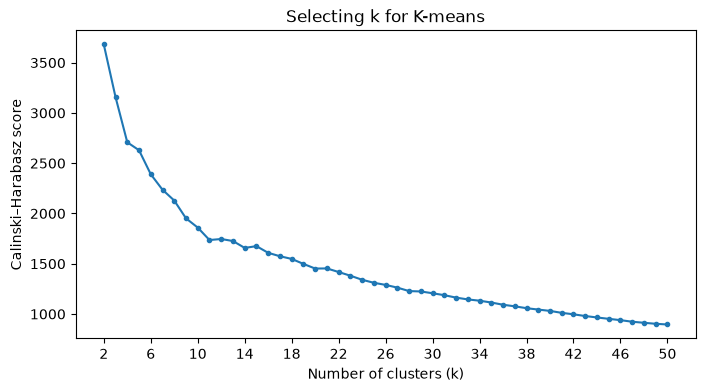

In [12]:
plt.figure(figsize=(8, 4))
plt.plot(list(k_values), ch_scores, marker=".")
plt.xlabel("Number of clusters (k)")
plt.ylabel("Calinski–Harabasz score")
plt.title("Selecting k for K-means")
plt.xticks(range(2, 51, 4))
plt.show()

**Answer:**

After applying K-Means tot he full dataset, we recireved the highest Calinski–Harabasz score for k=2, which we set as our best k. 

### (b) Determine which family is the majority

In [13]:
model = KMeans(
    n_clusters=best_k,
    random_state=552,
    n_init=1,
    max_iter=100
)
cluster_ids = model.fit_predict(X)

cluster_majorities = []

for cluster_id in np.unique(cluster_ids):
    mask = cluster_ids == cluster_id
    majority = y.loc[mask].mode().iloc[0]

    cluster_majorities.append({
        "Cluster": cluster_id,
        "Family": majority["Family"],
        "Genus": majority["Genus"],
        "Species": majority["Species"],
        "Number of observations": int(mask.sum())
    })

cluster_majorities_df = pd.DataFrame(cluster_majorities)
cluster_majorities_df.sort_values("Cluster").reset_index(drop=True)

,Cluster,Family,Genus,Species,Number of observations
0,0,Hylidae,Hypsiboas,HypsiboasCordobae,3597
1,1,Leptodactylidae,Adenomera,AdenomeraHylaedactylus,3598


**Answer:**

The two clusters contained 3,597 and 3,598 observations. Cluster 0’s majority labels were Hylidae, Hypsiboas, and HypsiboasCordobae; Cluster 1’s were Leptodactylidae, Adenomera, and AdenomeraHylaedactylus.

### (c) Calculate the average Hamming distance, Hamming score, and Hamming loss

In [ ]:
results = []

for run in range(50):
    model = KMeans(
        n_clusters=best_k,
        random_state=run,
        n_init=1,
        max_iter=100
    )
    cluster_ids = model.fit_predict(X)

    predictions = pd.DataFrame(
        index=y.index,
        columns=target_cols
    )

    for cluster_id in np.unique(cluster_ids):
        mask = cluster_ids == cluster_id
        majority = y.loc[mask].mode().iloc[0]
        predictions.loc[mask, :] = majority.to_numpy()

    label_losses = [
        hamming_loss(y[col], predictions[col])
        for col in target_cols
    ]

    run_hamming_loss = np.mean(label_losses)
    run_hamming_score = 1 - run_hamming_loss
    run_hamming_distance = run_hamming_loss * len(target_cols)

    results.append({
        "Hamming distance": run_hamming_distance,
        "Hamming score": run_hamming_score,
        "Hamming loss": run_hamming_loss
    })

results_df = pd.DataFrame(results)

summary = pd.DataFrame({
    "Mean": results_df.mean(),
    "Standard deviation": results_df.std()
})

summary

,Mean,Standard deviation
Hamming distance,0.895622,1.121495e-16
Hamming score,0.701459,1.121495e-16
Hamming loss,0.298541,5.607473e-17


**Answer:**

Across 50 repetitions, the mean Hamming distance was 0.8956 incorrect labels per observation, with a standard deviation effectively equal to zero. The mean Hamming score was 0.7015 and the mean Hamming loss was 0.2985, indicating that about 70.15% of the labels matched the cluster majority labels on average.

## 3. ISLR 12.6.2

The dissimilarities are $d_{12}=0.30$, $d_{13}=0.40$, $d_{14}=0.70$, $d_{23}=0.50$, $d_{24}=0.80$, and $d_{34}=0.45$.

### a. Complete Linkage

**Answer:**

Observations 1 and 2 fuse first at height $0.30$. Observations 3 and 4 fuse next at height $0.45$. The complete-linkage distance between clusters $\{1,2\}$ and $\{3,4\}$ is the largest pairwise dissimilarity between their observations, $0.80$. Therefore, the two clusters fuse at height $0.80$.

```text
Height
0.80          ┌───────────────┐
              │               │
0.45          │       ┌───────┴───────┐
              │       │               │
0.30      ┌───┴───┐   │               │
          │       │   │               │
0.00      1       2   3               4

### b. Single Linkage

**Answer:**

Observations 1 and 2 fuse first at height $0.30$.

The distance between cluster $\{1,2\}$ and observation 3 is $\min(0.40,0.50)=0.40$, so observation 3 joins that cluster at height $0.40$.

The distance from cluster $\{1,2,3\}$ to observation 4 is $\min(0.70,0.80,0.45)=0.45$, so observation 4 joins at height $0.45$.

```text
Height
0.45      ┌───────────────────────────────┐
          │                               │
0.40      │               ┌───────────────┴───┐
          │               │                   │
0.30  ┌───┴───┐           │                   │
      │       │           │                   │
0.00  1       2           3                   4
```

### c. 

**Answer:** Cutting the complete-linkage dendrogram between heights of $0.45$ and $0.80$ produce the two clusters $\{1,2\}$ and $\{3,4\}$.

### d.

**Answer:** Cutting the single-linkage dendrogram between the hights of $0.40$ and $0.45$ produce the two clusters $\{1,2,3\}$ and $\{4\}$.

### e.

**Answer:**

The following dendrogram is equivalent to the one in part (a). The positions of observations 1 and 2 are swapped, as are the positions of observations 3 and 4. The fusion heights and cluster memberships remain the same.

```text
Height
0.80          ┌───────────────────────────────┐
              │                               │
0.45          │               ┌───────────────┴───────────────┐
              │               │                               │
0.30      ┌───┴───┐           │                               │
          │       │           │                               │
0.00      2       1           4                               3
```